# F1 Overtake Window Predictor — Milestone 1

**Team JanusForge:** Amine, Owen, Joshua, Idris  
**Course:** Deep Learning · **Dataset:** Five 2024 Formula 1 races · **Source:** [OpenF1](https://openf1.org/docs/)

**Task:** Given the preceding 30 seconds of race telemetry and the current gap/position of a following driver, predict whether that driver will overtake the car directly ahead in the **next 60 seconds**.

## 1. Setup and data source

The source race CSV files and preprocessing scripts are included in our [GitHub repository](https://github.com/amineelmess/f1-overtake-window-predictor-JanusForge). We clone it into a Colab runtime, install dependencies, and verify the five race directories.

**Races:** Bahrain (9472), Australia (9488), Spain (9539), Austria (9550), São Paulo (9636).

In [1]:
import subprocess
import sys
from pathlib import Path

# we install the packages needed by preprocessing, training and evaluation.
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q",
     "numpy", "pandas>=2.0", "scikit-learn", "matplotlib", "torch", "joblib"],
    check=True,
)

REPO_URL = "https://github.com/amineelmess/f1-overtake-window-predictor-JanusForge.git"
REPO_DIR = Path("/content/f1-overtake-window-predictor-JanusForge")

if REPO_DIR.exists():
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)

DATA_DIR = REPO_DIR / "data"
PROCESSED = DATA_DIR / "processed"
RACES = {9472: "Bahrain", 9488: "Australia", 9539: "Spain",
         9550: "Austria", 9636: "São Paulo"}

for session_key, race in RACES.items():
    folder = DATA_DIR / "2024" / "races" / str(session_key)
    assert (folder / "car_data").is_dir(), f"Missing telemetry folder: {race}"
    assert (folder / "overtakes.csv").is_file(), f"Missing race data: {race}"
    print(f"{race}: {len(list((folder / 'car_data').glob('driver_*.csv')))} driver telemetry files")

assert (REPO_DIR / "finalize_dataset.py").is_file()
assert (REPO_DIR / "preprocess_all_races.py").is_file()
print("Setup complete.")

Bahrain: 20 driver telemetry files
Australia: 19 driver telemetry files
Spain: 20 driver telemetry files
Austria: 20 driver telemetry files
São Paulo: 20 driver telemetry files
Setup complete.


## 2. Dataset construction and preprocessing

The scripts below reproduce the preprocessing from the repository. They:

1. Reconstruct driver positions every **10 seconds**, pair each car with the car immediately ahead, and attach recently reported time gaps.
2. Restrict observations to positive gaps of at most **3 seconds**. Remove snapshots affected by nearby pit stops, yellow flags, safety cars, VSC, red flags, or race finish.
3. Construct provisional binary labels using recorded overtakes in the **following 60 seconds**; cross-check their position changes and mark ambiguous cases as uncertain and exclude them.
4. Summarize both drivers' speed, throttle, brake, RPM and DRS from the **preceding 30 seconds**. Correct brake/DRS encodings and reject incomplete telemetry windows.
5. Keep complete races separate between training, validation, and test to prevent overlapping observation windows leaking across splits.


In [3]:
# Run the fully reproducible preprocessing and feature generation pipeline.
# This produces all_races_features.csv, feature_columns.json, and train/val/test.csv.
subprocess.run(
    [sys.executable, str(REPO_DIR / "finalize_dataset.py")],
    cwd=str(REPO_DIR),
    check=True,
)
print("Dataset preparation done.")

Dataset preparation done.


In [4]:
import json
import numpy as np
import pandas as pd
from IPython.display import display

with open(PROCESSED / "feature_columns.json", encoding="utf-8") as f:
    feature_columns = json.load(f)

train = pd.read_csv(PROCESSED / "train.csv")
val = pd.read_csv(PROCESSED / "val.csv")
test = pd.read_csv(PROCESSED / "test.csv")
all_data = pd.read_csv(PROCESSED / "all_races_features.csv")

assert len(feature_columns) == 16
assert len(all_data) == len(train) + len(val) + len(test)
assert not all_data[feature_columns + ["label"]].isna().any().any()
assert set(train["race"]).isdisjoint(set(val["race"]))
assert set(train["race"]).isdisjoint(set(test["race"]))
assert set(val["race"]).isdisjoint(set(test["race"]))

summary = pd.DataFrame([
    {"Split": "Train", "Races": ", ".join(sorted(train["race"].unique())),
     "Rows": len(train), "Positive": int(train["label"].sum())},
    {"Split": "Validation", "Races": ", ".join(sorted(val["race"].unique())),
     "Rows": len(val), "Positive": int(val["label"].sum())},
    {"Split": "Test", "Races": ", ".join(sorted(test["race"].unique())),
     "Rows": len(test), "Positive": int(test["label"].sum())},
])
print("Total observations:", len(all_data), "| Positive:", int(all_data["label"].sum()))
print("Model input features:", feature_columns)
display(summary)
print("Example labeled data (Bahrain):")
display(all_data.loc[all_data["race"].eq("Bahrain"),
                     ["race", "time", "driver_number", "driver_ahead",
                      "position", "gap_seconds", "label"]].head(5))

Total observations: 17719 | Positive: 665
Model input features: ['gap_seconds', 'position', 'follower_speed_mean', 'ahead_speed_mean', 'relative_speed_mean', 'follower_speed_last', 'ahead_speed_last', 'relative_speed_last', 'follower_throttle_mean', 'ahead_throttle_mean', 'follower_brake_frac', 'ahead_brake_frac', 'follower_rpm_mean', 'ahead_rpm_mean', 'follower_drs_active_frac', 'ahead_drs_active_frac']


,Split,Races,Rows,Positive
0,Train,"Austria, Bahrain, Spain",11095,497
1,Validation,Australia,2733,62
2,Test,São Paulo,3891,106


Example labeled data (Bahrain):


,race,time,driver_number,driver_ahead,position,gap_seconds,label
0,Bahrain,2024-03-02 15:05:42.341000+00:00,18,77,19,1.766,0
1,Bahrain,2024-03-02 15:05:42.341000+00:00,23,22,11,0.429,0
2,Bahrain,2024-03-02 15:05:42.341000+00:00,22,44,10,0.577,0
3,Bahrain,2024-03-02 15:05:42.341000+00:00,63,16,3,0.542,0
4,Bahrain,2024-03-02 15:05:42.341000+00:00,20,23,12,0.432,0


## 3. Baseline: majority class

Since Overtakes are rare, our baseline always outputs **no overtake** (class 0). It has **zero trainable parameters**. We evaluate baseline and neural network on the **same held-out São Paulo test observations**. Accuracy alone is misleading for this imbalanced classification task: our main metric is **average precision (AP / PR-AUC)**, supplemented by precision, recall and F1.

In [5]:
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix,
    precision_score, recall_score, f1_score,
    precision_recall_curve, ConfusionMatrixDisplay,
)


def score_model(name, y_true, y_pred, y_score):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "PR-AUC": average_precision_score(y_true, y_score),
    }

baseline_rows = []
for name, frame in [("Validation", val), ("Test", test)]:
    y = frame["label"].to_numpy(dtype=int)
    constant = np.zeros(len(y), dtype=int)
    baseline_rows.append({"Dataset": name, **score_model("Always no overtake", y, constant, constant.astype(float))})

baseline_results = pd.DataFrame(baseline_rows)
display(baseline_results.round(4))
baseline_results.to_csv(PROCESSED / "baseline_results.csv", index=False)

,Dataset,Model,Accuracy,Precision,Recall,F1,PR-AUC
0,Validation,Always no overtake,0.9773,0.0,0.0,0.0,0.0227
1,Test,Always no overtake,0.9728,0.0,0.0,0.0,0.0272


## 4. Simple model: Feedforward Neural Network (FNN)

**Architecture:** 16 input features → 32 ReLU units → dropout 0.15 → 16 ReLU units → 1 output logit (**1,089 trainable parameters**). **Optimizer:** Adam, learning rate 0.001, batch size 256. **Loss:** weighted binary cross-entropy to address class imbalance. **Selection:** best **validation** average precision, with early stopping (patience 10, maximum 60 epochs). Input standardization is fit to training data only. The classification threshold maximizes **validation** F1 and is frozen before the held-out test.

The loss weighting improves sensitivity but means sigmoid scores are not necessarily calibrated probabilities.

In [6]:
import copy
import joblib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
scaler = StandardScaler()
X_train = scaler.fit_transform(train[feature_columns]).astype("float32")
X_val = scaler.transform(val[feature_columns]).astype("float32")
y_train = train["label"].to_numpy(dtype="float32")
y_val = val["label"].to_numpy(dtype="float32")

loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train).unsqueeze(1)),
    batch_size=256, shuffle=True,
)
X_val_tensor = torch.from_numpy(X_val).to(device)
y_val_tensor = torch.from_numpy(y_val).unsqueeze(1).to(device)

model = nn.Sequential(
    nn.Linear(len(feature_columns), 32), nn.ReLU(), nn.Dropout(0.15),
    nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1),
).to(device)
parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert parameters == 1089, f"Unexpected parameter count: {parameters}"

pos_weight = (len(y_train) - int(y_train.sum())) / int(y_train.sum())
criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor([pos_weight], dtype=torch.float32, device=device)
)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

history, best_ap, best_state, best_epoch, no_improvement = [], -1.0, None, 0, 0
for epoch in range(1, 61):
    model.train()
    total_train_loss = 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item() * len(xb)

    model.eval()
    with torch.no_grad():
        val_logits = model(X_val_tensor)
        val_loss = criterion(val_logits, y_val_tensor).item()
        val_scores = torch.sigmoid(val_logits).cpu().numpy().ravel()
    val_ap = average_precision_score(y_val, val_scores)
    history.append({"epoch": epoch, "train_loss": total_train_loss / len(train),
                    "val_loss": val_loss, "val_ap": val_ap})

    if val_ap > best_ap + 1e-5:
        best_ap, best_epoch = val_ap, epoch
        best_state = copy.deepcopy(model.state_dict())
        no_improvement = 0
    else:
        no_improvement += 1

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d}: train loss {history[-1]['train_loss']:.4f}, "
              f"validation loss {val_loss:.4f}, validation AP {val_ap:.4f}")
    if no_improvement >= 10:
        print("Early stopping triggered.")
        break

model.load_state_dict(best_state)
model.eval()
print(f"Best epoch: {best_epoch} | Validation AP: {best_ap:.4f} | Trainable parameters: {parameters}")

Epoch 01: train loss 1.2722, validation loss 0.8724, validation AP 0.0504
Epoch 05: train loss 0.7575, validation loss 0.6227, validation AP 0.1191
Epoch 10: train loss 0.6844, validation loss 0.5880, validation AP 0.1472
Epoch 15: train loss 0.6547, validation loss 0.5835, validation AP 0.1690
Epoch 20: train loss 0.6300, validation loss 0.5842, validation AP 0.1640
Early stopping triggered.
Best epoch: 13 | Validation AP: 0.1809 | Trainable parameters: 1089


Validation results (chosen threshold):
Threshold: 0.8609


,Model,Accuracy,Precision,Recall,F1,PR-AUC
0,FNN,0.9623,0.2644,0.371,0.3087,0.1809


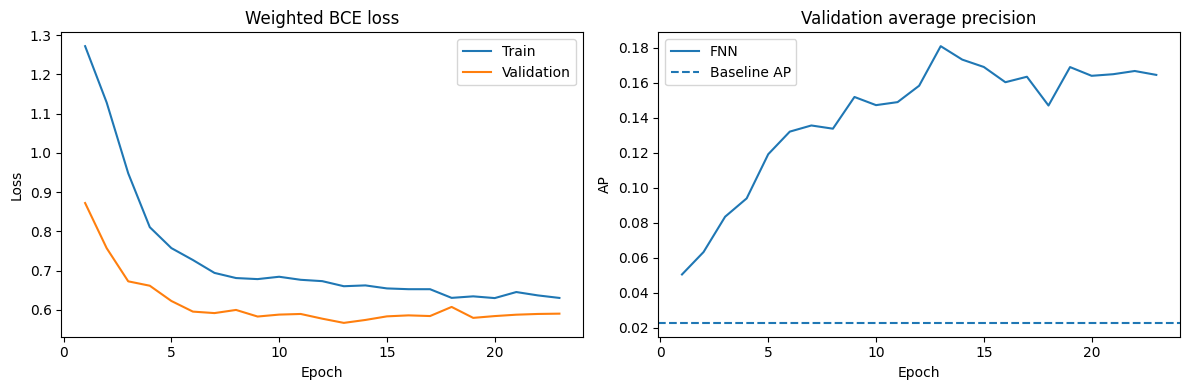

In [7]:
# Select threshold from VALIDATION predictions (no test race).
with torch.no_grad():
    val_probabilities = torch.sigmoid(model(X_val_tensor)).cpu().numpy().ravel()

precision_curve, recall_curve, thresholds = precision_recall_curve(y_val, val_probabilities)
val_f1_curve = (2 * precision_curve[:-1] * recall_curve[:-1] /
                np.maximum(precision_curve[:-1] + recall_curve[:-1], 1e-12))
best_threshold = float(thresholds[np.argmax(val_f1_curve)])
val_predictions = (val_probabilities >= best_threshold).astype(int)

print("Validation results (chosen threshold):")
print("Threshold:", round(best_threshold, 4))
display(pd.DataFrame([score_model("FNN", y_val.astype(int), val_predictions, val_probabilities)]).round(4))

training_history = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(training_history["epoch"], training_history["train_loss"], label="Train")
axes[0].plot(training_history["epoch"], training_history["val_loss"], label="Validation")
axes[0].set(title="Weighted BCE loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
axes[1].plot(training_history["epoch"], training_history["val_ap"], label="FNN")
axes[1].axhline(y_val.mean(), ls="--", label="Baseline AP")
axes[1].set(title="Validation average precision", xlabel="Epoch", ylabel="AP")
axes[1].legend()
plt.tight_layout()
plt.savefig(PROCESSED / "training_curves.png", dpi=180)
plt.show()

# Persist artifacts for reproduction and reporting.
torch.save(best_state, PROCESSED / "mlp_best.pt")
joblib.dump(scaler, PROCESSED / "feature_scaler.joblib")
training_history.to_csv(PROCESSED / "training_history.csv", index=False)
with open(PROCESSED / "mlp_config.json", "w", encoding="utf-8") as f:
    json.dump({"best_epoch": best_epoch, "threshold": best_threshold,
               "feature_columns": feature_columns}, f, indent=2)

## 5. Final held-out test: São Paulo 2024

The model weights, feature scaler and decision threshold are **fixed** before test evaluation. São Paulo contributes 3,891 observations (106 positives). We use the same test examples for the majority-class baseline and FNN.

===== HELD-OUT SÃO PAULO TEST RESULTS =====
Test windows: 3891 | Positive windows: 106
Fixed validation threshold: 0.8609


,Model,Accuracy,Precision,Recall,F1,PR-AUC
0,Always no overtake,0.9728,0.0000,0.0000,0.0000,0.0272
1,FNN,0.9465,0.1645,0.2358,0.1938,0.1148


FNN confusion matrix [actual rows × predicted columns]:
 [[3658  127]
 [  81   25]]
TN: 3658 FP: 127 FN: 81 TP: 25


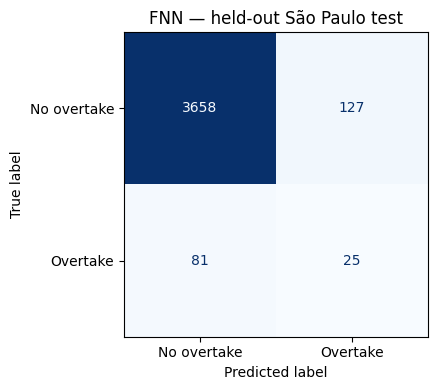

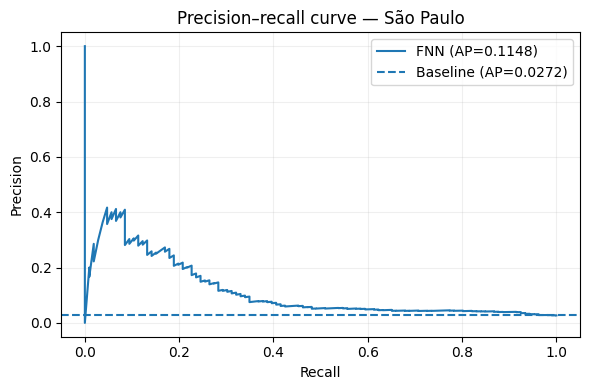

In [8]:
# we evaluate the trained best checkpoint on the untouched test split.
X_test = scaler.transform(test[feature_columns]).astype("float32")
y_test = test["label"].to_numpy(dtype=int)

model.eval()
with torch.no_grad():
    test_probabilities = torch.sigmoid(
        model(torch.from_numpy(X_test).to(device))
    ).cpu().numpy().ravel()

test_predictions = (test_probabilities >= best_threshold).astype(int)
baseline_predictions = np.zeros_like(y_test)
comparison = pd.DataFrame([
    score_model("Always no overtake", y_test, baseline_predictions,
                np.zeros(len(y_test), dtype=float)),
    score_model("FNN", y_test, test_predictions, test_probabilities),
])
print("===== HELD-OUT SÃO PAULO TEST RESULTS =====")
print("Test windows:", len(y_test), "| Positive windows:", int(y_test.sum()))
print("Fixed validation threshold:", round(best_threshold, 4))
display(comparison.round(4))

cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
print("FNN confusion matrix [actual rows × predicted columns]:\n", cm)
print("TN:", cm[0, 0], "FP:", cm[0, 1], "FN:", cm[1, 0], "TP:", cm[1, 1])
comparison.to_csv(PROCESSED / "test_comparison.csv", index=False)

predictions_table = test.copy()
predictions_table["mlp_score"] = test_probabilities
predictions_table["mlp_prediction"] = test_predictions
predictions_table.to_csv(PROCESSED / "test_predictions.csv", index=False)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["No overtake", "Overtake"]).plot(
    ax=ax, cmap="Blues", colorbar=False
)
ax.set_title("FNN — held-out São Paulo test")
plt.tight_layout()
plt.savefig(PROCESSED / "test_confusion_matrix.png", dpi=180)
plt.show()

curve_p, curve_r, _ = precision_recall_curve(y_test, test_probabilities)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(curve_r, curve_p, label=f"FNN (AP={average_precision_score(y_test, test_probabilities):.4f})")
ax.axhline(y_test.mean(), ls="--", label=f"Baseline (AP={y_test.mean():.4f})")
ax.set(xlabel="Recall", ylabel="Precision", title="Precision–recall curve — São Paulo")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.savefig(PROCESSED / "test_precision_recall.png", dpi=180)
plt.show()

## 6. Error analysis and limitations

We group test predictions by the time gap to the leading car. Positive predictions can be false alarms when a car is very close but fails to pass within 60 seconds. Windows sampled every 10 seconds overlap heavily, so these metrics are about observation windows, **not independent overtaking maneuvers**.

In [9]:
errors = predictions_table.copy()
conditions = [
    (errors["label"] == 1) & (errors["mlp_prediction"] == 1),
    (errors["label"] == 0) & (errors["mlp_prediction"] == 1),
    (errors["label"] == 1) & (errors["mlp_prediction"] == 0),
    (errors["label"] == 0) & (errors["mlp_prediction"] == 0),
]
errors["outcome"] = np.select(conditions, ["TP", "FP", "FN", "TN"], default="Unknown")
errors["gap_range"] = pd.cut(errors["gap_seconds"],
                             bins=[0, .5, 1, 2, 3.001],
                             labels=["0–0.5s", "0.5–1s", "1–2s", "2–3s"])
print("Error counts by time gap:")
display(pd.crosstab(errors["gap_range"], errors["outcome"]))

cols = ["time", "driver_number", "driver_ahead", "gap_seconds",
        "relative_speed_mean", "mlp_score"]
print("Top false-positive examples:")
display(errors.loc[errors["outcome"].eq("FP")].nlargest(5, "mlp_score")[cols])
print("Missed positive examples (nearest threshold):")
display(errors.loc[errors["outcome"].eq("FN")].nlargest(5, "mlp_score")[cols])
errors.to_csv(PROCESSED / "test_error_analysis.csv", index=False)

Error counts by time gap:


outcome,FN,FP,TN,TP
gap_range,,,,
0–0.5s,13,93,120,23
0.5–1s,44,34,1407,2
1–2s,19,0,1287,0
2–3s,5,0,844,0


Top false-positive examples:


,time,driver_number,driver_ahead,gap_seconds,relative_speed_mean,mlp_score
1408,2024-11-03 16:12:07.515000+00:00,27,14,0.466,23.819820,0.997614
1389,2024-11-03 16:11:57.515000+00:00,27,14,0.907,28.929204,0.995798
2085,2024-11-03 16:22:27.515000+00:00,55,43,0.351,30.037037,0.995191
2682,2024-11-03 17:25:07.515000+00:00,4,16,0.368,25.612069,0.992890
2006,2024-11-03 16:21:07.515000+00:00,11,55,0.469,19.796296,0.991305


Missed positive examples (nearest threshold):


,time,driver_number,driver_ahead,gap_seconds,relative_speed_mean,mlp_score
971,2024-11-03 16:04:37.515000+00:00,1,30,0.468,-0.629630,0.860531
2265,2024-11-03 17:05:37.515000+00:00,50,24,0.631,5.711712,0.841653
2471,2024-11-03 17:20:07.515000+00:00,50,24,0.105,-0.303571,0.840237
188,2024-11-03 15:53:47.515000+00:00,55,24,0.648,-1.027523,0.829368
2239,2024-11-03 17:05:17.515000+00:00,63,4,0.267,-0.229358,0.828388


## 7. Discussion and next steps

**Known limitations:** five races only; provisional event-based labels; many temporally overlapping windows; no tyre compound/age, weather or gap-trend features; class-weighted sigmoid outputs are not calibrated probabilities. The majority-class baseline can achieve high *accuracy* despite identifying zero overtakes, which is why AP/PR-AUC is the primary metric.

** For the next three weeks:** (1) we need to expand to more races and manually audit labels; (2) we need to add tyre, weather, track, and time-series features and compare a sequential architecture; (3) we then need to evaluate across multiple held-out races, assess calibration, and build a simple overtake-window visualization.
